In [1]:
import pandas as pd

# Load the dataset
data = pd.read_excel(r'C:\Users\shahu\OPEN CLASSROOMS\PROJET 3\outputs\data_modelisation.xlsx')
data.head()

,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),TotalGHGEmissions,hasEnergyStarScore,Age,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101,12,0,hotel,88434,NaN,0,NaN,0,60.000000,7456910,250,1,98,1.000000,0.529177,SEN,0
1,NonResidential,98101,11,15064,hotel,83880,parking,15064,restaurant,4622,61.000000,8664479,296,1,29,0.947775,0.374270,EN,1
2,NonResidential,98101,10,0,hotel,61320,NaN,0,NaN,0,56.000000,6946801,286,1,99,1.000000,0.398590,SEN,0
3,NonResidential,98121,18,62000,hotel,123445,parking,68009,NaN,0,75.000000,14656503,505,1,45,0.850914,0.366295,EN,0
4,Nonresidential COS,98101,2,37198,police station,88830,NaN,0,NaN,0,60.909091,12581712,302,0,26,0.850914,0.585885,EN,0


# MODELISATION WITHOUT ENERGYSTARScore

In [2]:

# Step 2: Drop the column
data = data.drop(columns=["hasEnergyStarScore"])
data = data.drop(columns=["ENERGYSTARScore"])
data.head()



,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUseWN(kBtu),TotalGHGEmissions,Age,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101,12,0,hotel,88434,NaN,0,NaN,0,7456910,250,98,1.000000,0.529177,SEN,0
1,NonResidential,98101,11,15064,hotel,83880,parking,15064,restaurant,4622,8664479,296,29,0.947775,0.374270,EN,1
2,NonResidential,98101,10,0,hotel,61320,NaN,0,NaN,0,6946801,286,99,1.000000,0.398590,SEN,0
3,NonResidential,98121,18,62000,hotel,123445,parking,68009,NaN,0,14656503,505,45,0.850914,0.366295,EN,0
4,Nonresidential COS,98101,2,37198,police station,88830,NaN,0,NaN,0,12581712,302,26,0.850914,0.585885,EN,0


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
import numpy as np
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler




# Identify categorical and numeric columns
cat_cols = data.select_dtypes(include=["object", "category"]).columns
num_cols = data.select_dtypes(exclude=["object", "category"]).columns.drop(["SiteEnergyUseWN(kBtu)", "TotalGHGEmissions"])

# Convert all categorical columns to string
for col in cat_cols:
    data[col] = data[col].astype(str)
print("✅ Converted categorical columns to string type for OneHotEncoder compatibility.")

# Preprocessing:
# - One-hot encode categorical
# - Scale numeric (needed for linear models, harmless for trees)
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])



✅ Converted categorical columns to string type for OneHotEncoder compatibility.


In [4]:
print(cat_cols)

Index(['BuildingType', 'ZipCode', 'LargestPropertyUseType',
       'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType',
       'EnergyMix'],
      dtype='object')


In [5]:
print(num_cols)

Index(['NumberofFloors', 'PropertyGFAParking', 'LargestPropertyUseTypeGFA',
       'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseTypeGFA',
       'Age', 'Ratio_LargestPropertyShare', 'Ratio_ElectricityShare',
       'isMixedProperty'],
      dtype='object')


In [6]:
data.head()

,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUseWN(kBtu),TotalGHGEmissions,Age,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101,12,0,hotel,88434,nan,0,nan,0,7456910,250,98,1.000000,0.529177,SEN,0
1,NonResidential,98101,11,15064,hotel,83880,parking,15064,restaurant,4622,8664479,296,29,0.947775,0.374270,EN,1
2,NonResidential,98101,10,0,hotel,61320,nan,0,nan,0,6946801,286,99,1.000000,0.398590,SEN,0
3,NonResidential,98121,18,62000,hotel,123445,parking,68009,nan,0,14656503,505,45,0.850914,0.366295,EN,0
4,Nonresidential COS,98101,2,37198,police station,88830,nan,0,nan,0,12581712,302,26,0.850914,0.585885,EN,0


In [7]:
pip install catboost

Note: you may need to restart the kernel to use updated packages.


In [8]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from catboost import CatBoostRegressor
from sklearn.dummy import DummyRegressor

models = {
    "Dummy": DummyRegressor(strategy="mean"),
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001, max_iter=50000),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "CatBoost": CatBoostRegressor(verbose=0, random_state=42)
}


In [9]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split
import pandas as pd

# Split data
features = [c for c in data.columns if c not in ["SiteEnergyUseWN(kBtu)", "TotalGHGEmissions"]]
X = data[features]
y_energy = data["SiteEnergyUseWN(kBtu)"]
y_ghg = data["TotalGHGEmissions"]

X_train, X_test, y_train_e, y_test_e = train_test_split(X, y_energy, test_size=0.2, random_state=42)
_, _, y_train_g, y_test_g = train_test_split(X, y_ghg, test_size=0.2, random_state=42)

# Results storage
results = []

for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    
    # Train & predict Energy
    pipe.fit(X_train, y_train_e)
    y_pred_e = pipe.predict(X_test)
    r2_e = r2_score(y_test_e, y_pred_e)
    rmse_e = np.sqrt(mean_squared_error(y_test_e, y_pred_e))
    mape_e = mean_absolute_percentage_error(y_test_e, y_pred_e)
    
    # Train & predict GHG
    pipe.fit(X_train, y_train_g)
    y_pred_g = pipe.predict(X_test)
    r2_g = r2_score(y_test_g, y_pred_g)
    rmse_g = np.sqrt(mean_squared_error(y_test_g, y_pred_g))
    mape_g = mean_absolute_percentage_error(y_test_g, y_pred_g)
    
    results.append({
        "Model": name,
        "R2_Energy": r2_e,
        "RMSE_Energy": rmse_e,
        "MAPE_Energy": mape_e,
        "R2_GHG": r2_g,
        "RMSE_GHG": rmse_g,
        "MAPE_GHG": mape_g
    })

# Display comparison
results_df = pd.DataFrame(results).sort_values(by="R2_Energy", ascending=False)
display(results_df)


c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.288e+15, tolerance: 9.519e+12
  model = cd_fast.sparse_enet_coordinate_descent(


,Model,R2_Energy,RMSE_Energy,MAPE_Energy,R2_GHG,RMSE_GHG,MAPE_GHG
5,GradientBoosting,0.778929,3.720231e+06,0.965742,0.647816,104.669128,1.460101
4,RandomForest,0.777817,3.729576e+06,0.885109,0.686865,98.696079,0.967767
6,CatBoost,0.756078,3.907772e+06,0.859890,0.654167,103.721124,1.365381
2,Ridge,0.678596,4.485691e+06,1.288676,0.345375,142.702042,3.569579
3,Lasso,0.630709,4.808266e+06,1.372110,0.194284,158.316041,3.881803
1,LinearRegression,0.629173,4.818249e+06,1.377978,0.190070,158.729419,3.893384
0,Dummy,-0.000289,7.913464e+06,3.758272,-0.000904,176.453397,7.493740


In [10]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import make_scorer, r2_score, mean_squared_error, mean_absolute_percentage_error
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

# 2. Define CV
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Define scoring
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

scoring = {
    "r2": make_scorer(r2_score),
    "rmse": make_scorer(rmse, greater_is_better=False),
    "mape": make_scorer(mean_absolute_percentage_error, greater_is_better=False)
}

# 4. CROSS-VALIDATION (on TRAINING data)
cv_results = []

for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    
    # --- Energy Cross-Validation ---
    scores_e_r2 = cross_val_score(pipe, X_train, y_train_e, cv=cv, scoring="r2")
    scores_e_rmse = cross_val_score(pipe, X_train, y_train_e, cv=cv, scoring=scoring["rmse"])
    scores_e_mape = cross_val_score(pipe, X_train, y_train_e, cv=cv, scoring=scoring["mape"])
    
    # --- GHG Cross-Validation ---
    scores_g_r2 = cross_val_score(pipe, X_train, y_train_g, cv=cv, scoring="r2")
    scores_g_rmse = cross_val_score(pipe, X_train, y_train_g, cv=cv, scoring=scoring["rmse"])
    scores_g_mape = cross_val_score(pipe, X_train, y_train_g, cv=cv, scoring=scoring["mape"])
    
    cv_results.append({
        "Model": name,
        "R2_Energy_Mean": np.mean(scores_e_r2),
        "R2_Energy_SD": np.std(scores_e_r2),
        "RMSE_Energy_Mean": -np.mean(scores_e_rmse),
        "RMSE_Energy_SD": np.std(scores_e_rmse),
        "MAPE_Energy_Mean": -np.mean(scores_e_mape),
        "MAPE_Energy_SD": np.std(scores_e_mape),
        "R2_GHG_Mean": np.mean(scores_g_r2),
        "R2_GHG_SD": np.std(scores_g_r2),
        "RMSE_GHG_Mean": -np.mean(scores_g_rmse),
        "RMSE_GHG_SD": np.std(scores_g_rmse),
        "MAPE_GHG_Mean": -np.mean(scores_g_mape),
        "MAPE_GHG_SD": np.std(scores_g_mape),
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(by="R2_Energy_Mean", ascending=False)
print("✅ Cross-Validation Results (5-fold on Training Data):\n")
display(cv_results_df)

# 5. FINAL EVALUATION (on TEST data - once only)
print("\n" + "="*80)
print("📊 FINAL TEST SET EVALUATION")
print("="*80 + "\n")

test_results = []

for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    
    # Train on FULL training set
    pipe.fit(X_train, y_train_e)
    y_pred_e = pipe.predict(X_test)
    r2_e_test = r2_score(y_test_e, y_pred_e)
    rmse_e_test = rmse(y_test_e, y_pred_e)
    mape_e_test = mean_absolute_percentage_error(y_test_e, y_pred_e)
    
    # Train on FULL training set
    pipe.fit(X_train, y_train_g)
    y_pred_g = pipe.predict(X_test)
    r2_g_test = r2_score(y_test_g, y_pred_g)
    rmse_g_test = rmse(y_test_g, y_pred_g)
    mape_g_test = mean_absolute_percentage_error(y_test_g, y_pred_g)
    
    test_results.append({
        "Model": name,
        "R2_Energy_Test": r2_e_test,
        "RMSE_Energy_Test": rmse_e_test,
        "MAPE_Energy_Test": mape_e_test,
        "R2_GHG_Test": r2_g_test,
        "RMSE_GHG_Test": rmse_g_test,
        "MAPE_GHG_Test": mape_g_test,
    })

test_results_df = pd.DataFrame(test_results).sort_values(by="R2_Energy_Test", ascending=False)
print("Test Set Results:\n")
display(test_results_df)


c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.694e+15, tolerance: 7.617e+12
  model = cd_fast.sparse_enet_coordinate_descent(
c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.334e+15, tolerance: 7.130e+12
  model = cd_fast.sparse_enet_coordinate_descent(
c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regular

✅ Cross-Validation Results (5-fold on Training Data):



,Model,R2_Energy_Mean,R2_Energy_SD,RMSE_Energy_Mean,RMSE_Energy_SD,MAPE_Energy_Mean,MAPE_Energy_SD,R2_GHG_Mean,R2_GHG_SD,RMSE_GHG_Mean,RMSE_GHG_SD,MAPE_GHG_Mean,MAPE_GHG_SD
6,CatBoost,0.695581,0.031586,4.726004e+06,356196.661446,0.725865,0.136137,0.641274,0.051283,120.293453,16.376138,3.275181e+13,6.550363e+13
5,GradientBoosting,0.675075,0.028717,4.882814e+06,312202.799776,0.864624,0.176665,0.561708,0.047144,133.005596,16.434911,5.775115e+12,1.155023e+13
2,Ridge,0.664776,0.068332,4.946294e+06,624444.143698,1.149129,0.157709,0.464702,0.123851,147.000759,26.939342,3.215734e+14,6.431468e+14
4,RandomForest,0.646491,0.035827,5.094205e+06,385356.065625,0.778552,0.199241,0.580173,0.056917,130.643988,21.007629,4.283697e+13,8.567395e+13
1,LinearRegression,0.645838,0.077379,5.075217e+06,630898.439340,1.201627,0.195124,0.409324,0.158999,153.558405,26.549121,3.484665e+14,6.969330e+14
3,Lasso,0.636880,0.062105,5.146918e+06,493088.159610,1.182814,0.180007,0.407895,0.152060,153.792076,25.659495,3.483771e+14,6.967541e+14
0,Dummy,-0.004345,0.002318,8.614228e+06,718914.112734,3.068093,0.369420,-0.001986,0.002443,201.321293,22.235361,4.382696e+14,8.765393e+14



📊 FINAL TEST SET EVALUATION



c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.288e+15, tolerance: 9.519e+12
  model = cd_fast.sparse_enet_coordinate_descent(


Test Set Results:



,Model,R2_Energy_Test,RMSE_Energy_Test,MAPE_Energy_Test,R2_GHG_Test,RMSE_GHG_Test,MAPE_GHG_Test
5,GradientBoosting,0.778929,3.720231e+06,0.965742,0.647816,104.669128,1.460101
4,RandomForest,0.777817,3.729576e+06,0.885109,0.686865,98.696079,0.967767
6,CatBoost,0.756078,3.907772e+06,0.859890,0.654167,103.721124,1.365381
2,Ridge,0.678596,4.485691e+06,1.288676,0.345375,142.702042,3.569579
3,Lasso,0.630709,4.808266e+06,1.372110,0.194284,158.316041,3.881803
1,LinearRegression,0.629173,4.818249e+06,1.377978,0.190070,158.729419,3.893384
0,Dummy,-0.000289,7.913464e+06,3.758272,-0.000904,176.453397,7.493740


In [11]:
from sklearn.model_selection import RandomizedSearchCV, train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error
import numpy as np
import pandas as pd

# 1. SPLIT DATA
X_train, X_test, y_train_e, y_test_e, y_train_g, y_test_g = train_test_split(
    X, y_energy, y_ghg, test_size=0.2, random_state=42
)

print("="*80)
print("STEP 1: HYPERPARAMETER TUNING - RandomizedSearchCV (200 Samples)")
print("="*80)

# 2. EXPANDED Hyperparameter grid for RandomForest
param_grid = {
    "model__n_estimators": [200, 400, 600],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", None, 0.5],
    "model__bootstrap": [True, False],
}

print(f"\n📊 Parameter Space:")
print(f"   n_estimators: {param_grid['model__n_estimators']}")
print(f"   max_depth: {param_grid['model__max_depth']}")
print(f"   min_samples_split: {param_grid['model__min_samples_split']}")
print(f"   min_samples_leaf: {param_grid['model__min_samples_leaf']}")
print(f"   max_features: {param_grid['model__max_features']}")
print(f"   bootstrap: {param_grid['model__bootstrap']}")
total_combinations = (
    len(param_grid["model__n_estimators"]) *
    len(param_grid["model__max_depth"]) *
    len(param_grid["model__min_samples_split"]) *
    len(param_grid["model__min_samples_leaf"]) *
    len(param_grid["model__max_features"]) *
    len(param_grid["model__bootstrap"])
)
print(f"\n   Total possible combinations: {total_combinations:,}")
print(f"   Sampling: 200 random combinations (~{200/total_combinations*100:.2f}% of total)\n")

# 3. TUNE FOR ENERGY using RandomizedSearchCV
print("🔍 Tuning for ENERGY prediction (RandomizedSearchCV)...")
pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

random_search_e = RandomizedSearchCV(
    pipe,
    param_grid,
    n_iter=200,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

random_search_e.fit(X_train, y_train_e)

print(f"\n✓ Best params for Energy:")
for key, value in random_search_e.best_params_.items():
    print(f"   {key}: {value}")
print(f"✓ Best CV R² (Energy): {random_search_e.best_score_:.4f}")

# 4. TUNE FOR GHG using RandomizedSearchCV
print("\n🔍 Tuning for GHG prediction (RandomizedSearchCV)...")
pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

random_search_g = RandomizedSearchCV(
    pipe,
    param_grid,
    n_iter=200,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

random_search_g.fit(X_train, y_train_g)

print(f"\n✓ Best params for GHG:")
for key, value in random_search_g.best_params_.items():
    print(f"   {key}: {value}")
print(f"✓ Best CV R² (GHG): {random_search_g.best_score_:.4f}")

# 5. CROSS-VALIDATION CONFIRMATION
print("\n" + "="*80)
print("STEP 2: CROSS-VALIDATION CONFIRMATION (on Training Data)")
print("="*80)

best_model_e = random_search_e.best_estimator_
best_model_g = random_search_g.best_estimator_

cv_scores_e = cross_val_score(best_model_e, X_train, y_train_e, cv=5, scoring="r2")
cv_scores_g = cross_val_score(best_model_g, X_train, y_train_g, cv=5, scoring="r2")

print(f"\n✓ Energy - CV R² Mean: {cv_scores_e.mean():.4f} ± {cv_scores_e.std():.4f}")
print(f"✓ GHG - CV R² Mean: {cv_scores_g.mean():.4f} ± {cv_scores_g.std():.4f}")

# 6. FINAL EVALUATION on TEST data
print("\n" + "="*80)
print("STEP 3: FINAL EVALUATION (on Test Data - ONCE)")
print("="*80)

# Energy
y_pred_e = best_model_e.predict(X_test)
r2_e = r2_score(y_test_e, y_pred_e)
rmse_e = np.sqrt(mean_squared_error(y_test_e, y_pred_e))
mape_e = mean_absolute_percentage_error(y_test_e, y_pred_e)

# GHG
y_pred_g = best_model_g.predict(X_test)
r2_g = r2_score(y_test_g, y_pred_g)
rmse_g = np.sqrt(mean_squared_error(y_test_g, y_pred_g))
mape_g = mean_absolute_percentage_error(y_test_g, y_pred_g)

print("\n📊 ENERGY Results:")
print(f"   R² Score: {r2_e:.4f}")
print(f"   RMSE: {rmse_e:.4f}")
print(f"   MAPE: {mape_e:.4f}")

print("\n📊 GHG Results:")
print(f"   R² Score: {r2_g:.4f}")
print(f"   RMSE: {rmse_g:.4f}")
print(f"   MAPE: {mape_g:.4f}")

# 7. Summary table
results_summary = pd.DataFrame({
    "Target": ["Energy", "GHG"],
    "CV_R2_Mean": [cv_scores_e.mean(), cv_scores_g.mean()],
    "CV_R2_Std": [cv_scores_e.std(), cv_scores_g.std()],
    "Test_R2": [r2_e, r2_g],
    "Test_RMSE": [rmse_e, rmse_g],
    "Test_MAPE": [mape_e, mape_g]
})

print("\n" + "="*80)
print("SUMMARY: Cross-Validation vs. Test Performance")
print("="*80 + "\n")
display(results_summary)

# 8. TOP 15 parameter combinations tested
print("\n" + "="*80)
print("TOP 15 PARAMETER COMBINATIONS (Energy)")
print("="*80 + "\n")

cv_results_df = pd.DataFrame(random_search_e.cv_results_)
top_15 = cv_results_df[[
    'param_model__n_estimators',
    'param_model__max_depth',
    'param_model__min_samples_split',
    'param_model__min_samples_leaf',
    'param_model__max_features',
    'param_model__bootstrap',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]].sort_values('rank_test_score').head(15)

top_15.columns = ['n_estimators', 'max_depth', 'min_split', 'min_leaf', 'max_features', 'bootstrap', 'Mean_R2', 'Std_R2', 'Rank']
display(top_15)

# 9. Distribution of tested combinations
print("\n" + "="*80)
print("DISTRIBUTION OF 200 SAMPLED COMBINATIONS")
print("="*80 + "\n")

sampled_params = pd.DataFrame({
    'n_estimators': cv_results_df['param_model__n_estimators'],
    'max_depth': cv_results_df['param_model__max_depth'],
    'min_samples_split': cv_results_df['param_model__min_samples_split'],
    'min_samples_leaf': cv_results_df['param_model__min_samples_leaf'],
    'max_features': cv_results_df['param_model__max_features'],
    'bootstrap': cv_results_df['param_model__bootstrap']
})

print("n_estimators distribution:")
print(sampled_params['n_estimators'].value_counts().sort_index())
print("\nmax_depth distribution:")
print(sampled_params['max_depth'].value_counts().sort_index())
print("\nmin_samples_split distribution:")
print(sampled_params['min_samples_split'].value_counts().sort_index())







STEP 1: HYPERPARAMETER TUNING - RandomizedSearchCV (200 Samples)

📊 Parameter Space:
   n_estimators: [200, 400, 600]
   max_depth: [10, 15, 20, None]
   min_samples_split: [2, 5, 10]
   min_samples_leaf: [1, 2, 4]
   max_features: ['sqrt', 'log2', None, 0.5]
   bootstrap: [True, False]

   Total possible combinations: 864
   Sampling: 200 random combinations (~23.15% of total)

🔍 Tuning for ENERGY prediction (RandomizedSearchCV)...
Fitting 5 folds for each of 200 candidates, totalling 1000 fits

✓ Best params for Energy:
   model__n_estimators: 600
   model__min_samples_split: 2
   model__min_samples_leaf: 1
   model__max_features: 0.5
   model__max_depth: 20
   model__bootstrap: True
✓ Best CV R² (Energy): 0.6564

🔍 Tuning for GHG prediction (RandomizedSearchCV)...
Fitting 5 folds for each of 200 candidates, totalling 1000 fits

✓ Best params for GHG:
   model__n_estimators: 400
   model__min_samples_split: 2
   model__min_samples_leaf: 1
   model__max_features: 0.5
   model__max_dep

,Target,CV_R2_Mean,CV_R2_Std,Test_R2,Test_RMSE,Test_MAPE
0,Energy,0.656365,0.035449,0.779115,3.718665e+06,0.953143
1,GHG,0.551956,0.038604,0.691926,9.789525e+01,1.021734



TOP 15 PARAMETER COMBINATIONS (Energy)



,n_estimators,max_depth,min_split,min_leaf,max_features,bootstrap,Mean_R2,Std_R2,Rank
5,600,20,2,1,0.5,True,0.656365,0.035449,1
43,600,20,5,1,0.5,True,0.655747,0.035598,2
7,400,20,2,1,0.5,True,0.655669,0.036598,3
27,200,None,10,1,0.5,True,0.655182,0.032753,4
128,400,None,10,1,0.5,True,0.653493,0.033661,5
145,400,15,10,1,0.5,True,0.652187,0.034802,6
102,200,15,5,1,0.5,True,0.650875,0.038208,7
122,400,10,2,1,0.5,True,0.648695,0.037606,8
143,200,10,5,1,0.5,True,0.648398,0.038832,9
158,200,10,2,1,0.5,True,0.647726,0.039576,10



DISTRIBUTION OF 200 SAMPLED COMBINATIONS

n_estimators distribution:
n_estimators
200    64
400    69
600    67
Name: count, dtype: int64

max_depth distribution:
max_depth
10    53
15    44
20    46
Name: count, dtype: int64

min_samples_split distribution:
min_samples_split
2     69
5     70
10    61
Name: count, dtype: int64



FEATURE IMPORTANCES (Top 20) - ENERGY model
                                              Feature  Importance
0                      num__LargestPropertyUseTypeGFA    0.432156
1                num__SecondLargestPropertyUseTypeGFA    0.115411
2                                 num__NumberofFloors    0.065981
3                 num__ThirdLargestPropertyUseTypeGFA    0.044261
4                         num__Ratio_ElectricityShare    0.033718
5                     num__Ratio_LargestPropertyShare    0.028354
6                             num__PropertyGFAParking    0.026230
7                                            num__Age    0.024620
8              cat__LargestPropertyUseType_laboratory    0.020939
9   cat__LargestPropertyUseType_supermarket/grocer...    0.012881
10            cat__LargestPropertyUseType_data center    0.012583
11     cat__LargestPropertyUseType_college/university    0.010372
12  cat__LargestPropertyUseType_hospital (general ...    0.008795
13  cat__LargestPropertyUseType

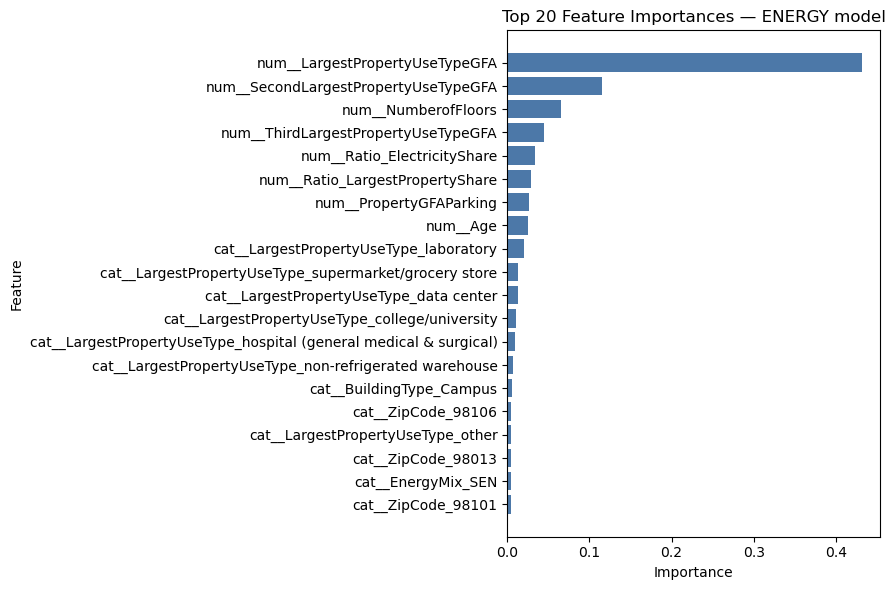

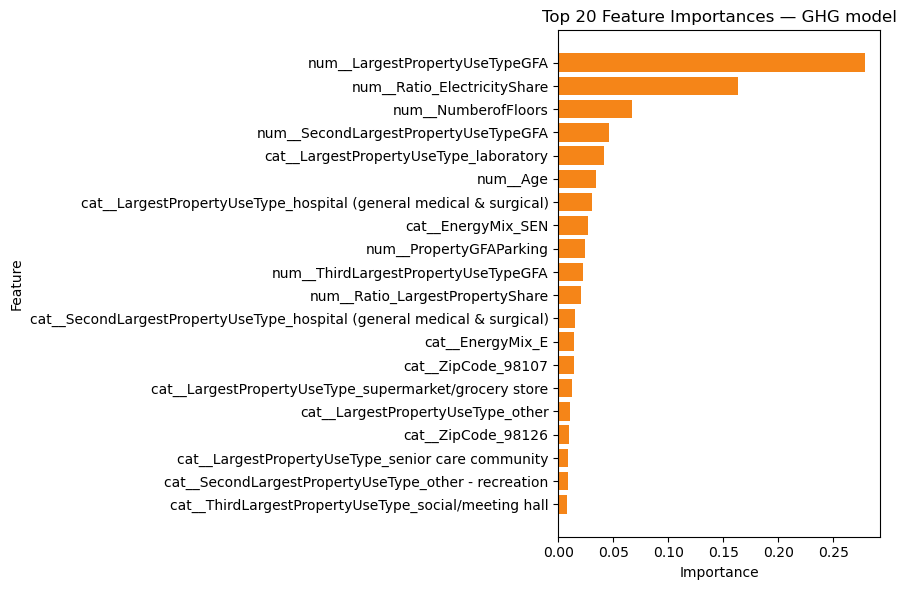

In [13]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
# Optional fallback if your model lacks feature_importances_
# from sklearn.inspection import permutation_importance

# ---------- Helpers ----------

def get_pipeline_feature_names(pipeline, X):
    """
    Return feature names after the pipeline's preprocessing step.
    - Supports ColumnTransformer and transformers with get_feature_names_out.
    - Falls back to numeric names based on transformed shape.
    """
    pre = None
    if hasattr(pipeline, "named_steps"):
        pre = pipeline.named_steps.get("preprocessor", None)

    if pre is None:
        if hasattr(X, "columns"):
            return list(X.columns)
        return [f"feature_{i}" for i in range(X.shape[1])]

    # Try standard API on the preprocessor
    try:
        if hasattr(pre, "get_feature_names_out"):
            names = pre.get_feature_names_out()
            return list(names)
    except Exception:
        pass

    # Handle ColumnTransformer with sub-transformers
    if isinstance(pre, ColumnTransformer):
        out_names = []
        for name, transformer, cols in pre.transformers_:
            if name == 'remainder' and transformer == 'drop':
                continue
            if transformer == 'drop':
                continue
            if transformer == 'passthrough':
                # passthrough columns
                if hasattr(cols, "__iter__"):
                    if hasattr(X, "columns"):
                        try:
                            out_names.extend(list(X.columns[cols] if hasattr(cols, "dtype") else cols))
                        except Exception:
                            out_names.extend(list(cols))
                    else:
                        out_names.extend(list(cols))
                else:
                    out_names.append(str(cols))
                continue
            # Try transformer get_feature_names_out
            try:
                if hasattr(transformer, "get_feature_names_out"):
                    base = transformer.get_feature_names_out(cols if hasattr(cols, "__iter__") else [cols])
                    out_names.extend(list(base))
                    continue
            except Exception:
                pass
            # As a fallback, infer output width to generate generic names
            try:
                X_part = X[cols] if hasattr(X, "loc") else X[:, cols]
                try:
                    Xt_part = transformer.transform(X_part)
                except Exception:
                    transformer = transformer.fit(X_part)
                    Xt_part = transformer.transform(X_part)
            except Exception:
                Xt_part = None
            if Xt_part is not None:
                n_out = Xt_part.shape[1] if len(getattr(Xt_part, "shape", [])) == 2 else 1
                base_cols = cols if hasattr(cols, "__iter__") else [cols]
                base_cols = list(base_cols)
                if len(base_cols) == 1 and n_out > 1:
                    out_names.extend([f"{name}__{base_cols[0]}_{i}" for i in range(n_out)])
                else:
                    for i in range(n_out):
                        out_names.append(f"{name}__{i}")
            else:
                # final fallback: at least add the column names
                if hasattr(cols, "__iter__"):
                    out_names.extend([f"{name}__{c}" for c in cols])
                else:
                    out_names.append(f"{name}__{cols}")
        if out_names:
            return out_names

    # Last-resort fallback: transform and use width
    try:
        Xt = pre.transform(X)
    except Exception:
        pre = pre.fit(X)
        Xt = pre.transform(X)
    n_out = Xt.shape[1]
    return [f"feature_{i}" for i in range(n_out)]


def extract_importances(pipeline):
    """
    Get final step name and feature_importances_ if available.
    """
    if not hasattr(pipeline, "named_steps"):
        return None, None
    final_step_name = list(pipeline.named_steps.keys())[-1]
    final_est = pipeline.named_steps[final_step_name]
    importances = getattr(final_est, "feature_importances_", None)
    return final_step_name, importances


def top_features_sorted(names, imps, top_n=20):
    """
    Build a DataFrame of top-N features sorted by importance descending.
    Includes a length check for safety.
    """
    if imps is None:
        return pd.DataFrame({"Feature": [], "Importance": []})
    if len(names) != len(imps):
        raise ValueError(f"Length mismatch: names={len(names)} vs importances={len(imps)}")
    df = pd.DataFrame({"Feature": names, "Importance": imps})
    df = df.sort_values("Importance", ascending=False).reset_index(drop=True)
    return df.head(top_n)


def plot_top_importances(df, title, figsize=(9, 6), color="#4C78A8"):
    """
    Plot a horizontal bar chart for a sorted top-N importance DataFrame.
    Expects columns: 'Feature', 'Importance' sorted desc already.
    """
    if df is None or df.empty:
        print(f"No importances to plot for: {title}")
        return
    # Reverse so the largest bar appears at the top
    df_plot = df.iloc[::-1]
    plt.figure(figsize=figsize)
    plt.barh(df_plot["Feature"], df_plot["Importance"], color=color)
    plt.title(title)
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


# ---------- Fit best pipelines, extract names/importances, sort, and plot ----------

# Assumes random_search_e and random_search_g already exist and are fitted RandomizedSearchCV objects
best_e = random_search_e.best_estimator_
best_g = random_search_g.best_estimator_

# Fit on training data
best_e.fit(X_train, y_train_e)
best_g.fit(X_train, y_train_g)

# Get transformed feature names per pipeline
feature_names_e = get_pipeline_feature_names(best_e, X_train)
feature_names_g = get_pipeline_feature_names(best_g, X_train)

# Extract final step and importances
final_step_name_e, importances_e = extract_importances(best_e)
final_step_name_g, importances_g = extract_importances(best_g)

# Build sorted top-N DataFrames
top_n = 20
top_e = top_features_sorted(feature_names_e, importances_e, top_n=top_n)
top_g = top_features_sorted(feature_names_g, importances_g, top_n=top_n)

# Display DataFrames
print("\nFEATURE IMPORTANCES (Top 20) - ENERGY model")
print(top_e)

print("\nFEATURE IMPORTANCES (Top 20) - GHG model")
print(top_g)

# Plot horizontal bar charts (sorted)
plot_top_importances(top_e, title="Top 20 Feature Importances — ENERGY model", color="#4C78A8")
plot_top_importances(top_g, title="Top 20 Feature Importances — GHG model", color="#F58518")
